In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/owid/energy-data/master/owid-energy-data.csv"

df = pd.read_csv(url)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Latest year:", df["year"].max())

df.head()

Rows: 23377
Columns: 130
Latest year: 2025


,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN


In [2]:
features = [
    "country",
    "year",
    "iso_code",
    "renewables_share_elec",
    "solar_share_elec",
    "wind_share_elec",
    "hydro_share_elec",
    "electricity_demand",
    "gdp",
    "population"
]

print("Available columns:")
print([col for col in features if col in df.columns])

print("\nMissing values:")
print(df[[col for col in features if col in df.columns]]
      .isnull().sum())

Available columns:
['country', 'year', 'iso_code', 'renewables_share_elec', 'solar_share_elec', 'wind_share_elec', 'hydro_share_elec', 'electricity_demand', 'gdp', 'population']

Missing values:
country                      0
year                         0
iso_code                  6112
renewables_share_elec    15505
solar_share_elec         15508
wind_share_elec          15716
hydro_share_elec         15600
electricity_demand       16999
gdp                      11597
population                4483
dtype: int64


In [3]:
# Step 3: Data Cleaning & Preparation

import pandas as pd

# Select relevant features
columns = [
    "country",
    "year",
    "iso_code",
    "renewables_share_elec",
    "solar_share_elec",
    "wind_share_elec",
    "hydro_share_elec",
    "electricity_demand",
    "gdp",
    "population"
]

energy = df[columns].copy()

# Keep individual countries and recent years
energy = energy[
    (energy["iso_code"].str.fullmatch(r"[A-Z]{3}", na=False)) &
    (energy["year"].between(2015, 2025))
].copy()

# Remove rows missing our main target
energy = energy.dropna(subset=["renewables_share_elec"])

# Remove duplicate country-year records
energy = energy.drop_duplicates(
    subset=["country", "year"]
)

# Sort data chronologically
energy = energy.sort_values(
    ["country", "year"]
).reset_index(drop=True)

print("Cleaned rows:", energy.shape[0])
print("Countries:", energy["country"].nunique())
print("Year range:", energy["year"].min(), "-", energy["year"].max())

print("\nMissing values after cleaning:")
print(energy.isnull().sum())

energy.head()

Cleaned rows: 2191
Countries: 212
Year range: 2015 - 2025

Missing values after cleaning:
country                    0
year                       0
iso_code                   0
renewables_share_elec      0
solar_share_elec           0
wind_share_elec           38
hydro_share_elec          35
electricity_demand         0
gdp                      871
population                 0
dtype: int64


,country,year,iso_code,renewables_share_elec,solar_share_elec,wind_share_elec,hydro_share_elec,electricity_demand,gdp,population
0,Afghanistan,2015,AFG,87.288,2.542,0.0,84.746,4.96,6.278339e+10,33831767.0
1,Afghanistan,2016,AFG,87.603,3.306,0.0,84.298,5.54,6.437222e+10,34700613.0
2,Afghanistan,2017,AFG,86.508,3.175,0.0,83.333,5.87,6.516928e+10,35688941.0
3,Afghanistan,2018,AFG,82.906,3.419,0.0,79.487,6.16,6.599674e+10,36743040.0
4,Afghanistan,2019,AFG,87.671,4.110,0.0,83.562,6.37,7.308570e+10,37856125.0


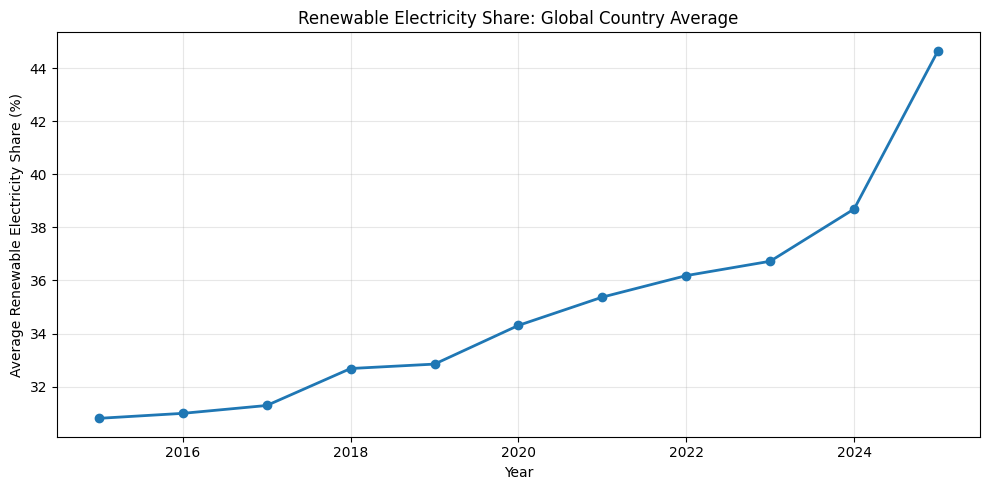

Average in 2015: 30.8 %
Average in 2025: 44.65 %


In [4]:
import matplotlib.pyplot as plt

# Global renewable electricity trend
global_trend = (
    energy.groupby("year")["renewables_share_elec"]
    .mean()
)

plt.figure(figsize=(10, 5))

plt.plot(
    global_trend.index,
    global_trend.values,
    marker="o",
    linewidth=2
)

plt.title("Renewable Electricity Share: Global Country Average")
plt.xlabel("Year")
plt.ylabel("Average Renewable Electricity Share (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Average in 2015:", round(global_trend.loc[2015], 2), "%")
print("Average in 2025:", round(global_trend.loc[2025], 2), "%")

Countries analyzed: 207
Optimal clusters: 5
Silhouette score: 0.501

Cluster profiles:
         solar_share_elec  wind_share_elec  hydro_share_elec
cluster                                                     
0                    3.45             1.58              8.08
1                   13.77            18.43             16.50
2                    2.32             1.45             74.24
3                   22.30             2.54             12.70
4                    7.12            39.00              7.19


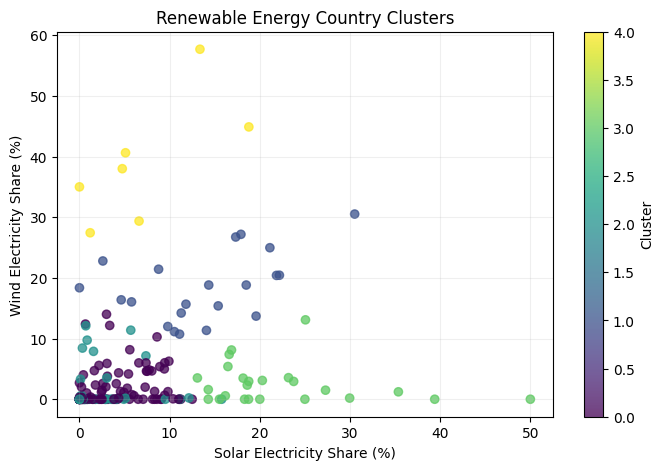

In [5]:
# Step 5: Renewable Energy Clustering

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Latest available observation per country
latest = (
    energy.sort_values("year")
    .groupby("country")
    .tail(1)
    .copy()
)

cluster_features = [
    "solar_share_elec",
    "wind_share_elec",
    "hydro_share_elec"
]

# Keep countries with complete feature values
cluster_data = latest.dropna(
    subset=cluster_features
).copy()

X = cluster_data[cluster_features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Compare possible numbers of clusters
scores = {}

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)

best_k = max(scores, key=scores.get)

final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_data["cluster"] = final_model.fit_predict(X_scaled)

print("Countries analyzed:", len(cluster_data))
print("Optimal clusters:", best_k)
print("Silhouette score:", round(scores[best_k], 3))

print("\nCluster profiles:")
print(
    cluster_data.groupby("cluster")[cluster_features]
    .mean().round(2)
)

plt.figure(figsize=(8, 5))
plt.scatter(
    cluster_data["solar_share_elec"],
    cluster_data["wind_share_elec"],
    c=cluster_data["cluster"],
    cmap="viridis",
    alpha=0.75
)
plt.xlabel("Solar Electricity Share (%)")
plt.ylabel("Wind Electricity Share (%)")
plt.title("Renewable Energy Country Clusters")
plt.colorbar(label="Cluster")
plt.grid(alpha=0.2)
plt.show()

In [6]:
# Step 6: Predictive Machine Learning

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

model_data = energy.sort_values(
    ["country", "year"]
).copy()

# Previous year's renewable share
model_data["previous_share"] = (
    model_data.groupby("country")["renewables_share_elec"]
    .shift(1)
)

# Predict next year's renewable share
model_data["next_share"] = (
    model_data.groupby("country")["renewables_share_elec"]
    .shift(-1)
)

model_data["next_year"] = (
    model_data.groupby("country")["year"]
    .shift(-1)
)

# Only use consecutive years
model_data = model_data[
    (model_data["next_year"] == model_data["year"] + 1)
].copy()

features_ml = [
    "renewables_share_elec",
    "previous_share",
    "solar_share_elec",
    "wind_share_elec",
    "hydro_share_elec"
]

model_data = model_data.dropna(
    subset=features_ml + ["next_share"]
)

# Train on historical years; test on 2024-2025
train = model_data[model_data["next_year"] <= 2023]
test = model_data[model_data["next_year"] >= 2024]

X_train = train[features_ml]
y_train = train["next_share"]

X_test = test[features_ml]
y_test = test["next_share"]

model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

# Baseline: assume no change from current year
baseline = test["renewables_share_elec"]

print("Training records:", len(train))
print("Testing records:", len(test))

print("\nBaseline MAE:",
      round(mean_absolute_error(y_test, baseline), 3))

print("Random Forest MAE:",
      round(mean_absolute_error(y_test, predictions), 3))

print("Random Forest R2:",
      round(r2_score(y_test, predictions), 3))

Training records: 1439
Testing records: 279

Baseline MAE: 1.965
Random Forest MAE: 2.144
Random Forest R2: 0.989


In [7]:
# Step 7: Compare a second ML model

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

boosting_model = HistGradientBoostingRegressor(
    max_iter=150,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

boosting_model.fit(X_train, y_train)

boosting_predictions = boosting_model.predict(X_test)

results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline),
        mean_absolute_error(y_test, predictions),
        mean_absolute_error(y_test, boosting_predictions)
    ]
})

print(results.round(3))
print(
    "\nGradient Boosting R2:",
    round(r2_score(y_test, boosting_predictions), 3)
)

               Model    MAE
0           Baseline  1.965
1      Random Forest  2.144
2  Gradient Boosting  2.159

Gradient Boosting R2: 0.989


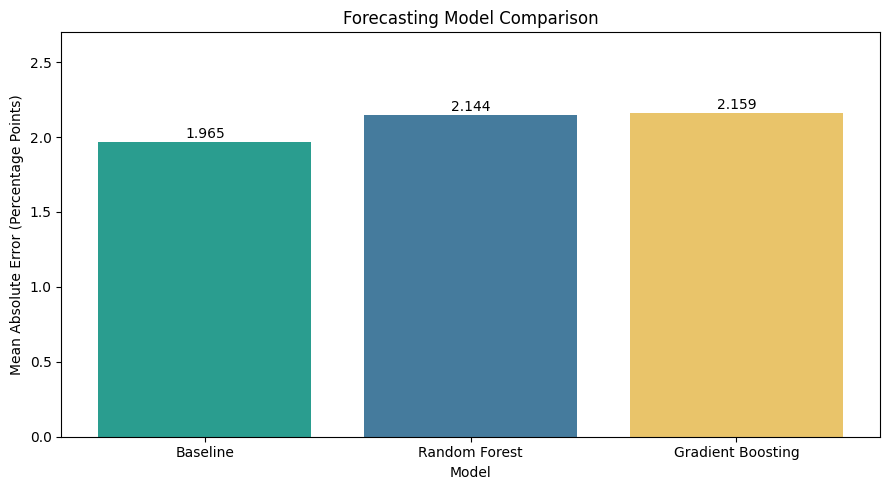

In [8]:
# Step 8: Model Performance Comparison

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(
    results["Model"],
    results["MAE"],
    color=["#2A9D8F", "#457B9D", "#E9C46A"]
)

plt.title("Forecasting Model Comparison")
plt.ylabel("Mean Absolute Error (Percentage Points)")
plt.xlabel("Model")
plt.ylim(0, results["MAE"].max() * 1.25)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{bar.get_height():.3f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()

In [9]:
# Step 9: Check temporal consistency

check = energy.sort_values(
    ["country", "year"]
).copy()

check["previous_year"] = (
    check.groupby("country")["year"].shift(1)
)

check["next_year"] = (
    check.groupby("country")["year"].shift(-1)
)

valid_rows = (
    (check["previous_year"] == check["year"] - 1) &
    (check["next_year"] == check["year"] + 1)
)

print("Rows with consecutive years:", valid_rows.sum())

print(
    "Rows excluded due to year gaps:",
    len(model_data) -
    model_data.index.isin(
        check.loc[valid_rows].index
    ).sum()
)

Rows with consecutive years: 1767
Rows excluded due to year gaps: 0
